# 01 · Datos de Stuttgart

**Qué hace:** verifica el archivo original, lo convierte al historial largo del contrato (CONTRATO, 2.1 y 2.2), lo valida con `rc_pronostico` y lo explora.

**Decisiones que aplica:** D-01 (solo `DEMAND_DATE`, los 7 platos e `ISHOLIDAY`), D-13 (los `TOTAL*` no son platos), D-05 (días cerrados = días sin fila), D-18 (huella SHA-256 y ficha de origen).

**Deja:** `dataset/stuttgart/FICHA.md`, `salidas/stuttgart/historial.parquet`, `salidas/stuttgart/calendario.json` y figuras en `resultados/exploracion/`.

In [1]:
# Parámetros
import hashlib, json
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
CSV = RAIZ / "dataset" / "stuttgart" / "data_preprocessed.csv"
SHA256_ESPERADO = "eb7d66f029043e000016015666410ab0b6921d268b20c290a01b1c8949673e8b"  # D-18
PLATOS = ["CALAMARI", "FISCH", "GARNELEN", "HAEHNCHEN", "KOEFTE", "LAMM", "STEAK"]
SALIDA = RAIZ / "salidas" / "stuttgart"
FIGURAS = RAIZ / "resultados" / "exploracion"
SALIDA.mkdir(parents=True, exist_ok=True); FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Huella del archivo
Si no coincide con la de D-18, la ejecución se detiene: no se sigue con otro archivo.

In [2]:
sha256 = hashlib.sha256(CSV.read_bytes()).hexdigest()
print(sha256)
assert sha256 == SHA256_ESPERADO, "El CSV no es el archivo de D-18; se detiene"


eb7d66f029043e000016015666410ab0b6921d268b20c290a01b1c8949673e8b


## 2. Lectura
Separador `;`, primera columna sin nombre (índice), fechas `mes.día.año`. Solo se leen las columnas de D-01; las otras ~280 (rezagos ya calculados, clima, totales) se ignoran.

In [3]:
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from rc_pronostico.contrato import validar_historial

crudo = pd.read_csv(CSV, sep=";", usecols=["DEMAND_DATE", *PLATOS, "ISHOLIDAY"])
crudo["fecha"] = pd.to_datetime(crudo["DEMAND_DATE"], format="%m.%d.%Y")
crudo = crudo.drop(columns="DEMAND_DATE").sort_values("fecha").reset_index(drop=True)
print(crudo.shape, crudo.fecha.min().date(), "→", crudo.fecha.max().date())
crudo.head()

(760, 9) 2013-10-04 → 2015-11-07


,CALAMARI,FISCH,GARNELEN,HAEHNCHEN,KOEFTE,LAMM,STEAK,ISHOLIDAY,fecha
0,6,6,12,40,23,50,36,0,2013-10-04
1,8,8,5,44,36,37,30,0,2013-10-05
2,6,5,11,19,12,22,16,0,2013-10-06
3,4,4,2,28,13,28,22,0,2013-10-07
4,7,4,9,22,18,29,29,0,2013-10-08


## 3. Calendario: días cerrados y feriados
Los días cerrados son los que **no tienen fila** dentro del rango (D-05). Los feriados vienen de `ISHOLIDAY`. Para que el historial sea continuo (CONTRATO, 2.1) esos días entran con 0 unidades, pero quedan declarados como cerrados, así que nunca son objetivo ni cuentan como 0 en rezagos y medias.

In [4]:
rango = pd.date_range(crudo.fecha.min(), crudo.fecha.max(), freq="D")
cerrados = rango.difference(pd.DatetimeIndex(crudo.fecha))
feriados = pd.DatetimeIndex(crudo.loc[crudo.ISHOLIDAY == 1, "fecha"])
print(f"{len(rango)} días en el rango, {len(crudo)} con fila, {len(cerrados)} cerrados:")
print([d.strftime("%Y-%m-%d (%a)") for d in cerrados])
print(f"{len(feriados)} feriados marcados en ISHOLIDAY")
assert crudo.fecha.is_unique

765 días en el rango, 760 con fila, 5 cerrados:
['2013-12-25 (Wed)', '2014-12-24 (Wed)', '2014-12-25 (Thu)', '2014-12-26 (Fri)', '2014-12-31 (Wed)']
22 feriados marcados en ISHOLIDAY


## 4. Historial largo del contrato

In [5]:
ancho = crudo.set_index("fecha")[PLATOS].reindex(rango).fillna(0).astype("int64")
largo = (ancho.rename_axis("fecha").reset_index()
         .melt(id_vars="fecha", var_name="producto_id", value_name="unidades"))
historial = validar_historial(largo)   # sale normalizado y ordenado
print(historial.shape, historial.producto_id.nunique(), "platos")
historial.head()

(5355, 3) 7 platos


,producto_id,fecha,unidades
0,CALAMARI,2013-10-04,6
1,CALAMARI,2013-10-05,8
2,CALAMARI,2013-10-06,6
3,CALAMARI,2013-10-07,4
4,CALAMARI,2013-10-08,7


## 5. Exploración

In [6]:
# Escala por plato (excluye días cerrados)
abiertos = historial[~historial.fecha.isin(cerrados)]
escala = abiertos.groupby("producto_id")["unidades"].agg(
    media="mean", mediana="median", p90=lambda s: s.quantile(.9), maximo="max",
    dias_en_cero=lambda s: int((s == 0).sum()))
escala.round(2).sort_values("media", ascending=False)

,media,mediana,p90,maximo,dias_en_cero
producto_id,,,,,
LAMM,31.64,30.0,48.0,88,1
HAEHNCHEN,30.40,29.0,46.0,93,1
STEAK,22.48,21.0,34.0,82,0
KOEFTE,22.09,21.0,33.1,71,0
GARNELEN,10.02,10.0,16.0,30,1
FISCH,4.69,4.0,8.0,17,21
CALAMARI,4.25,4.0,8.0,25,32


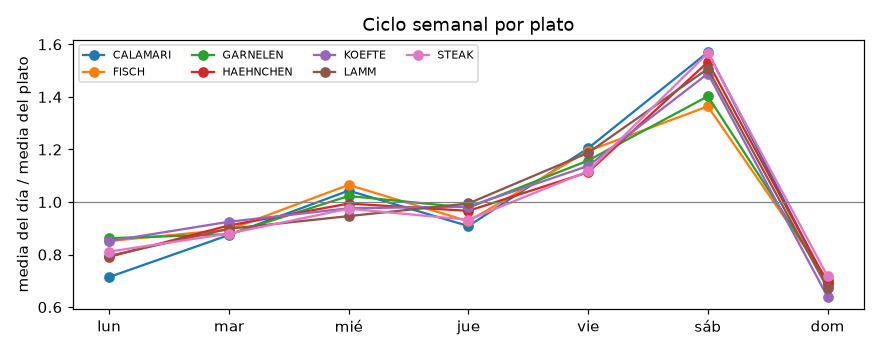

,lun,mar,mié,jue,vie,sáb,dom
producto_id,,,,,,,
CALAMARI,0.71,0.87,1.04,0.91,1.20,1.57,0.68
FISCH,0.85,0.89,1.07,0.93,1.19,1.36,0.70
GARNELEN,0.86,0.88,1.02,0.98,1.16,1.40,0.70
HAEHNCHEN,0.79,0.91,0.99,0.97,1.11,1.53,0.69
KOEFTE,0.85,0.92,0.98,0.98,1.14,1.49,0.64
LAMM,0.79,0.90,0.95,0.99,1.19,1.51,0.67
STEAK,0.81,0.88,0.97,0.93,1.12,1.57,0.72


In [7]:
# Ciclo semanal: media por día de la semana y plato, relativa a la media del plato
abiertos = abiertos.assign(dow=abiertos.fecha.dt.day_of_week)
ciclo = abiertos.pivot_table(index="producto_id", columns="dow", values="unidades", aggfunc="mean")
ciclo = ciclo.div(ciclo.mean(axis=1), axis=0)
ciclo.columns = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, ax = plt.subplots(figsize=(8, 3.2))
for plato, fila in ciclo.iterrows(): ax.plot(fila.index, fila.values, marker="o", label=plato)
ax.axhline(1, color="grey", lw=.8); ax.set_ylabel("media del día / media del plato")
ax.set_title("Ciclo semanal por plato"); ax.legend(ncol=4, fontsize=7); fig.tight_layout()
fig.savefig(FIGURAS / "stuttgart_ciclo_semanal.png", dpi=110); plt.close(fig)
display(Image(FIGURAS / "stuttgart_ciclo_semanal.png"))
ciclo.round(2)

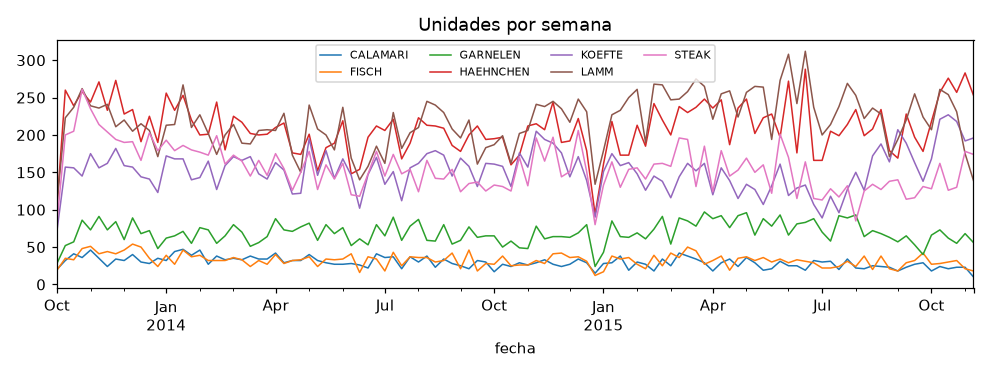

In [8]:
# Serie semanal por plato
semanal = abiertos.pivot_table(index=pd.Grouper(key="fecha", freq="W"), columns="producto_id", values="unidades", aggfunc="sum")
fig, ax = plt.subplots(figsize=(9, 3.4)); semanal.plot(ax=ax, lw=1)
ax.set_title("Unidades por semana"); ax.legend(ncol=4, fontsize=7); fig.tight_layout()
fig.savefig(FIGURAS / "stuttgart_serie_semanal.png", dpi=110); plt.close(fig)
display(Image(FIGURAS / "stuttgart_serie_semanal.png"))

In [9]:
# Navidad y Año Nuevo: alrededor de los días cerrados
navidad = historial[historial.fecha.between("2013-12-20", "2014-01-03") | historial.fecha.between("2014-12-20", "2015-01-03")]
tabla = navidad.pivot(index="fecha", columns="producto_id", values="unidades")
tabla["cerrado"] = tabla.index.isin(cerrados)
tabla

producto_id,CALAMARI,FISCH,GARNELEN,HAEHNCHEN,KOEFTE,LAMM,STEAK,cerrado
fecha,,,,,,,,
2013-12-20,7,4,11,32,38,57,30,False
2013-12-21,3,7,12,42,25,29,37,False
2013-12-22,4,4,10,17,5,13,25,False
2013-12-23,6,6,11,42,42,46,53,False
2013-12-24,1,3,1,3,4,7,5,False
2013-12-25,0,0,0,0,0,0,0,True
2013-12-26,4,0,3,12,2,16,18,False
2013-12-27,11,5,12,54,34,44,44,False
2013-12-28,7,5,17,52,31,40,40,False


In [10]:
# Días en cero entre los días abiertos
escala["dias_en_cero"].to_dict()

{'CALAMARI': 32,
 'FISCH': 21,
 'GARNELEN': 1,
 'HAEHNCHEN': 1,
 'KOEFTE': 0,
 'LAMM': 1,
 'STEAK': 0}

## 6. Ficha de origen (D-18) y salidas

In [11]:
FICHA = f'''# Ficha del dataset de Stuttgart

| Campo | Valor |
|---|---|
| Archivo | `data_preprocessed.csv` |
| Origen | Mendeley Data, "Data for: Machine learning for inventory management: Analyzing two concepts to get from data to decisions" |
| Autores | Fabian Taigel, Jan Meller |
| DOI | 10.17632/7s3ys9ntnz.1 |
| Licencia | CC BY 4.0 |
| SHA-256 | `{sha256}` |
| Tamaño | {CSV.stat().st_size} bytes |
| Filas con datos | {len(crudo)} de {len(rango)} días ({crudo.fecha.min().date()} a {crudo.fecha.max().date()}) |
| Días sin fila (cerrados) | {", ".join(d.strftime("%Y-%m-%d") for d in cerrados)} |
| Platos | {", ".join(PLATOS)} |
| Columnas usadas | `DEMAND_DATE` (formato mes.día.año), los 7 platos, `ISHOLIDAY` |
| Columnas ignoradas | el resto (rezagos, clima, totales `TOTAL*`; D-01, D-13) |

Generada por `cuadernos/01_datos_stuttgart.ipynb`. Citar la fuente al redistribuir.
'''
(CSV.parent / "FICHA.md").write_text(FICHA, encoding="utf-8")

historial.to_parquet(SALIDA / "historial.parquet", index=False)
calendario = {"dias_cerrados": [d.strftime("%Y-%m-%d") for d in cerrados],
              "feriados": [d.strftime("%Y-%m-%d") for d in feriados]}
(SALIDA / "calendario.json").write_text(json.dumps(calendario, indent=1), encoding="utf-8")
sorted(p.name for p in SALIDA.iterdir())

['calendario.json', 'historial.parquet']

## Verificaciones

In [12]:
assert sha256 == SHA256_ESPERADO
assert len(crudo) == 760 and len(rango) == 765, (len(crudo), len(rango))
assert len(cerrados) == 5, cerrados
assert all(d.month in (12, 1) for d in cerrados), "los cierres deben ser de Navidad/Año Nuevo"
assert historial.producto_id.nunique() == 7
assert not any(c.startswith("TOTAL") for c in historial.producto_id.unique())
assert len(historial) == 7 * 765
assert (historial.groupby("fecha").size() == 7).all()
assert set(calendario["dias_cerrados"]).isdisjoint(set(calendario["feriados"]))
assert escala.loc["CALAMARI", "dias_en_cero"] == 32, escala.loc["CALAMARI", "dias_en_cero"]
print("OK · historial de Stuttgart validado")

OK · historial de Stuttgart validado
